In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# Build and edit a game

A PGSolver row is `id priority owner successors "name";`, where owner 0 is
Even and 1 is Odd. Edit the text and press "Parse and solve". Parsing creates a
new immutable native game. The default input and the second example below run
automatically.

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
before,Even,1,1,1,1,1,1,True,0
before,Odd,2,1,2,1,1,1,True,0
after,Even,0,0,0,0,0,0,True,0
after,Odd,2,1,2,1,2,2,True,0


dominion: vertices covered by this player's attractor decomposition (its tree); won: every vertex this player wins, including vertices removed by preprocessing (+pre) or earlier shaving rounds (+iter); unresolved: vertices neither player's search certified.


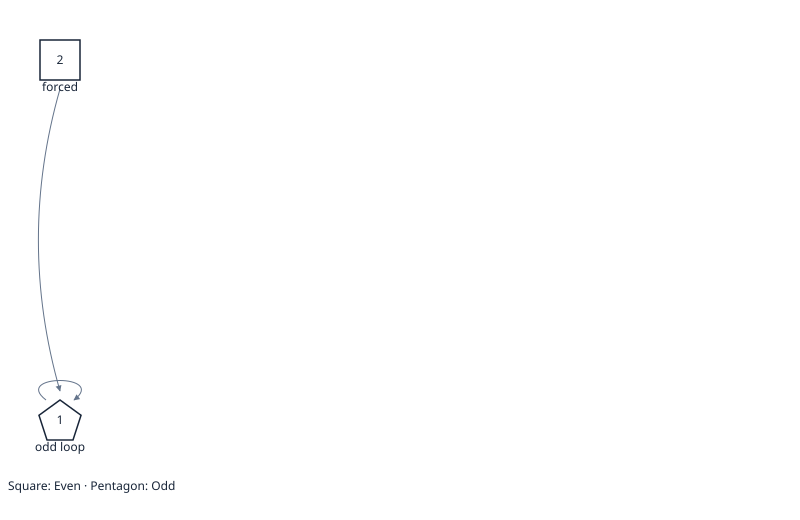

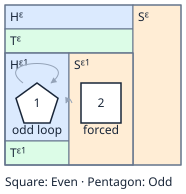

Static widget snapshot; rerun for interactive controls.

In [2]:
from notebook_support import editor
text = 'parity 1; 0 2 0 0,1 "choose"; 1 1 1 1 "odd loop";'
initial = strahler.Game.from_text(text)
changed = strahler.Game.from_text(text.replace('0,1 "choose"', '1 "forced"'))
before = strahler.decompose(initial, "zielonka")
after = strahler.decompose(changed, "zielonka")
assert before.regions[0] == frozenset({0})
assert after.regions[1] == frozenset({0, 1})
metrics_table({"before": before, "after": after})
display(GameView(changed), TreeView(after.trees[1], game=changed))
display(editor(text))

Remove the Even self-loop by replacing `0,1` with `1`. Even loses its choice
to remain at priority 2, and Odd then wins both vertices. The native parser
reports malformed rows and nonexistent successors before solving.